In [1]:
# %load_ext autoreload
%reload_ext autoreload
%autoreload 2

In [4]:
#!/usr/bin/env python3

import gtsam
import gtsam_unstable
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
%matplotlib widget
import numpy as np
np.set_printoptions(linewidth=np.inf, suppress=True)
import copy
import time
from pathlib import Path
import open3d as o3d
from scipy.spatial import KDTree
from dataclasses import asdict
import yaml
import pickle

# Local imports
import common.FGVizHelpers as fgtools
from params.params import Params
from multiSession.SessionManager import SessionManager

from sparcification.NFR import GraphSparsification
from ros2.readFromRosbags import GroundTruthLoader, ReadTopicsFromRosbag



# Check covariances for approximation of LinearContainerFactor

In [3]:
import re

def load_pose_cov_file(file_path):
    file_path = Path(file_path)
    records = []

    with file_path.open("r") as f:
        lines = f.readlines()

    # Skip the first line (header/info)
    for line in lines[1:]:
        line = line.strip()
        if not line:
            continue

        key_match = re.search(r"key:\s*([^\s]+)", line)
        pose_match = re.search(r"pose:\s*\[(.*?)\]\s*covariance:", line)
        cov_match = re.search(r"covariance:\s*\[(.*?)\]\s*$", line)

        if key_match is None or pose_match is None or cov_match is None:
            continue

        key = key_match.group(1)
        pose_flat = np.fromstring(pose_match.group(1), sep=" ")
        cov_flat = np.fromstring(cov_match.group(1), sep=" ")

        pose = pose_flat.reshape(4, 4)
        covariance = cov_flat.reshape(6, 6)

        records.append(
            {
                "key": key,
                "pose": pose,
                "covariance": covariance,
            }
        )

    return records


# Example usage
file_path_1 = Path("../denseMarginalization.txt")
data_dense = load_pose_cov_file(file_path_1)

print(f"Loaded {len(data_dense)} entries from {file_path_1}")
print(data_dense[0]["key"])
print(data_dense[0]["pose"])
print(data_dense[0]["covariance"])

FileNotFoundError: [Errno 2] No such file or directory: '../denseMarginalization.txt'

In [ ]:
data_MuSigma = load_pose_cov_file(Path("../approxMargWithMuSigma.txt"))
data_Schur = load_pose_cov_file(Path("../approxMargWithSchurComp.txt"))

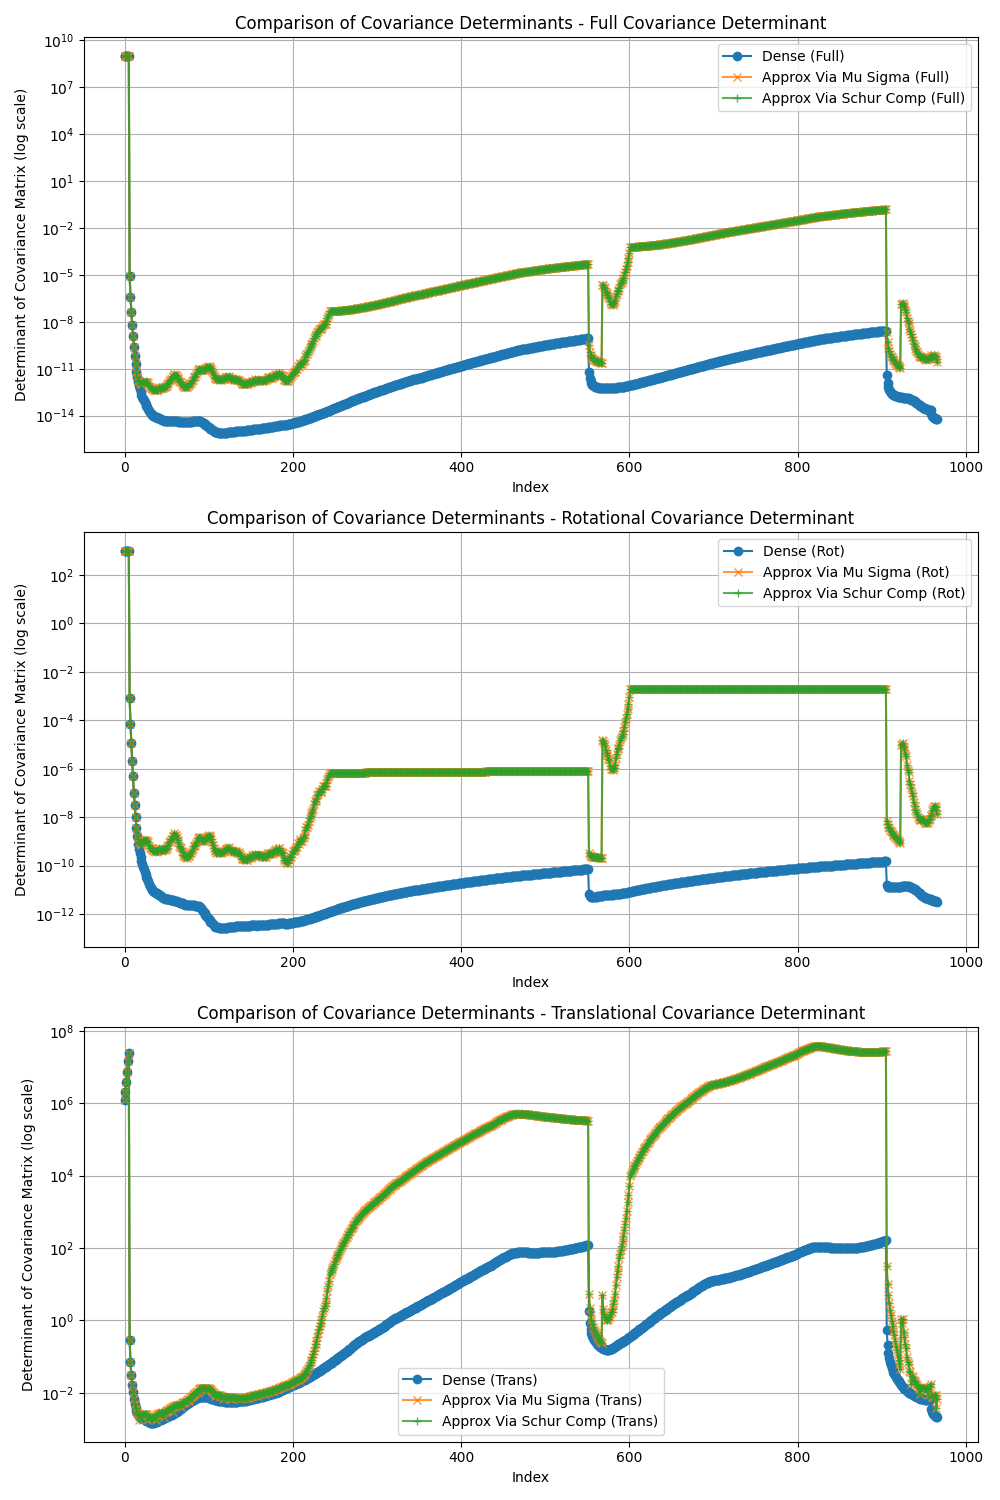

In [ ]:
# Find determinant of covariance matrices and compare 
det_dense = []
det_dense.append([np.linalg.det(record["covariance"]) for record in data_dense]) # Full covariance determinant
det_dense.append([np.linalg.det(record["covariance"][:3, :3]) for record in data_dense]) # Determinant of the top-left 3x3 block (rotational covariance)
det_dense.append([np.linalg.det(record["covariance"][3:, 3:]) for record in data_dense]) # Determinant of the bottom-right 3x3 block (translational covariance)

det_MuSigma = []
det_MuSigma.append([np.linalg.det(record["covariance"]) for record in data_MuSigma])
det_MuSigma.append([np.linalg.det(record["covariance"][:3, :3]) for record in data_MuSigma]) # Determinant of the top-left 3x3 block (rotational covariance)
det_MuSigma.append([np.linalg.det(record["covariance"][3:, 3:]) for record in data_MuSigma]) # Determinant of the bottom-right 3x3 block (translational covariance)

det_Schur = []
det_Schur.append([np.linalg.det(record["covariance"]) for record in data_Schur])
det_Schur.append([np.linalg.det(record["covariance"][:3, :3]) for record in data_Schur]) # Determinant of the top-left 3x3 block (rotational covariance)
det_Schur.append([np.linalg.det(record["covariance"][3:, 3:]) for record in data_Schur]) # Determinant of the bottom-right 3x3 block (translational covariance)


# Plot the determinants for comparison with a y axis in log scale
labels = ['Full', 'Rot', 'Trans']
titles = ['Full Covariance Determinant', 'Rotational Covariance Determinant', 'Translational Covariance Determinant']
fig, ax = plt.subplots(3, 1, figsize=(10, 15))
for i, (det1, det2, det3) in enumerate(zip(det_dense, det_MuSigma, det_Schur)):
    ax[i].set_yscale('log')
    ax[i].plot(det1, label=f'Dense ({labels[i]})', marker='o')
    ax[i].plot(det2, label=f'Approx Via Mu Sigma ({labels[i]})', alpha=0.8, marker='x')
    ax[i].plot(det3, label=f'Approx Via Schur Comp ({labels[i]})', alpha = 0.8, marker='+')
    ax[i].set_xlabel('Index')
    ax[i].set_ylabel('Determinant of Covariance Matrix (log scale)')
    ax[i].set_title(f'Comparison of Covariance Determinants - {titles[i]}')
    ax[i].legend()
    ax[i].grid()
plt.tight_layout()

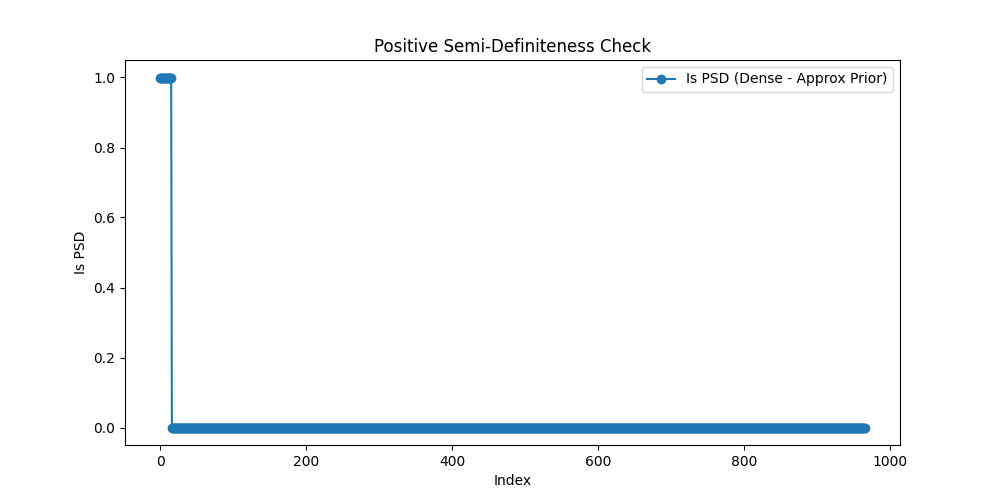

In [ ]:
import common.FGVizHelpers as fgtools
psd = []
for d1, d2 in zip(data_dense, data_MuSigma):
    cov1 = d1["covariance"]
    cov2 = d2["covariance"]
    psd.append(fgtools.isPSD(cov1 - cov2, printDebug=False))

plt.figure(figsize=(10, 5))
plt.plot(psd, label='Is PSD (Dense - Approx Prior)', marker='o')
plt.xlabel('Index')
plt.ylabel('Is PSD')
plt.title('Positive Semi-Definiteness Check')
plt.legend()

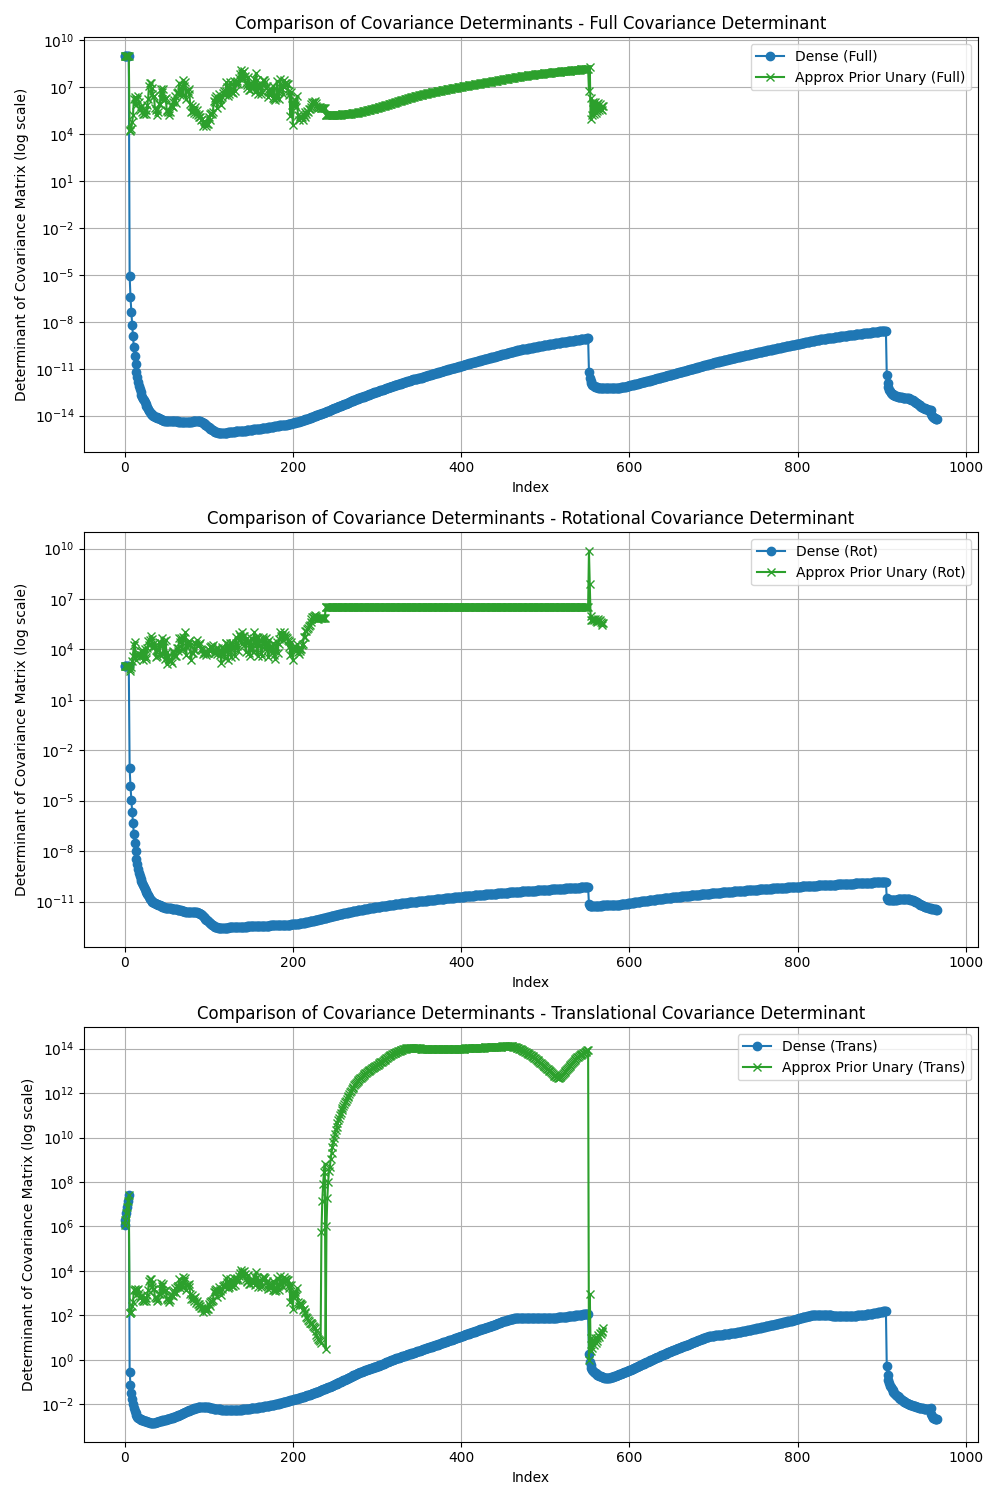

In [ ]:
file_path_3 = Path("../approxPrior.txt")
data_MuSigmaPrior = load_pose_cov_file(file_path_3)

det_MuSigmaPrior = []
det_MuSigmaPrior.append([np.linalg.det(record["covariance"]) for record in data_MuSigmaPrior])
det_MuSigmaPrior.append([np.linalg.det(record["covariance"][:3, :3]) for record in data_MuSigmaPrior]) # Determinant of the top-left 3x3 block (rotational covariance)
det_MuSigmaPrior.append([np.linalg.det(record["covariance"][3:, 3:]) for record in data_MuSigmaPrior]) # Determinant of the bottom-right 3x3 block (translational covariance)

# Plot the determinants for comparison with a y axis in log scale
labels = ['Full', 'Rot', 'Trans']
titles = ['Full Covariance Determinant', 'Rotational Covariance Determinant', 'Translational Covariance Determinant']
fig, ax = plt.subplots(3, 1, figsize=(10, 15))
for i, (det1, det2) in enumerate(zip(det_dense, det_MuSigmaPrior)):
    ax[i].set_yscale('log')
    ax[i].plot(det1, label=f'Dense ({labels[i]})', marker='o')
    ax[i].plot(det2, label=f'Approx Prior Unary ({labels[i]})', marker='x', color="tab:green")
    ax[i].set_xlabel('Index')
    ax[i].set_ylabel('Determinant of Covariance Matrix (log scale)')
    ax[i].set_title(f'Comparison of Covariance Determinants - {titles[i]}')
    ax[i].legend()
    ax[i].grid()
plt.tight_layout()

In [ ]:
def readTimeFromFile(filename):
    with open(filename, "r") as f:
        lines = f.readlines()
        data = [float(line.strip()) for line in lines]
        return data
    

data_mu_sigma = readTimeFromFile("../approximationTime_MuSigma.txt")
data_schurcomplement = readTimeFromFile("../approximationTime_SchurComplement.txt")



In [ ]:
print(data_mu_sigma)

[0.00011014938354492188, 0.00012946128845214844, 0.00021076202392578125, 0.00010347366333007812, 0.00012540817260742188, 0.00013566017150878906, 0.00010156631469726562, 0.00018548965454101562, 0.00013637542724609375, 0.00010323524475097656, 0.00012826919555664062, 0.00017070770263671875, 0.00022673606872558594, 0.00011849403381347656, 0.00013375282287597656, 0.00019669532775878906, 0.00021600723266601562, 0.0002002716064453125, 0.00024509429931640625, 0.0001342296600341797, 0.0001933574676513672, 0.00021886825561523438, 0.00010824203491210938, 0.00020956993103027344, 0.00010156631469726562, 0.00012159347534179688, 0.00012183189392089844, 0.00011706352233886719, 0.0002562999725341797, 0.000102996826171875, 0.00010371208190917969, 0.00010585784912109375, 0.00011587142944335938, 0.00015115737915039062, 0.00012683868408203125, 0.00010585784912109375, 0.0002079010009765625, 0.00014019012451171875, 0.00021409988403320312, 0.00020003318786621094, 0.00018358230590820312, 0.0002372264862060547,

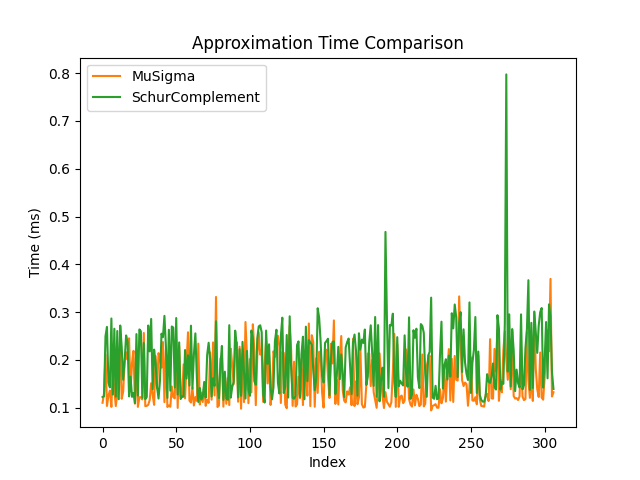

In [ ]:
plt.close("Timing")
plt.figure("Timing")
plt.plot(np.asarray(data_mu_sigma)*1e3, label="MuSigma", color="tab:orange")
plt.plot(np.asarray(data_schurcomplement)*1e3, label="SchurComplement", color="tab:green")
plt.title("Approximation Time Comparison")
plt.xlabel("Index")
plt.ylabel("Time (ms)")
plt.legend()
plt.show()

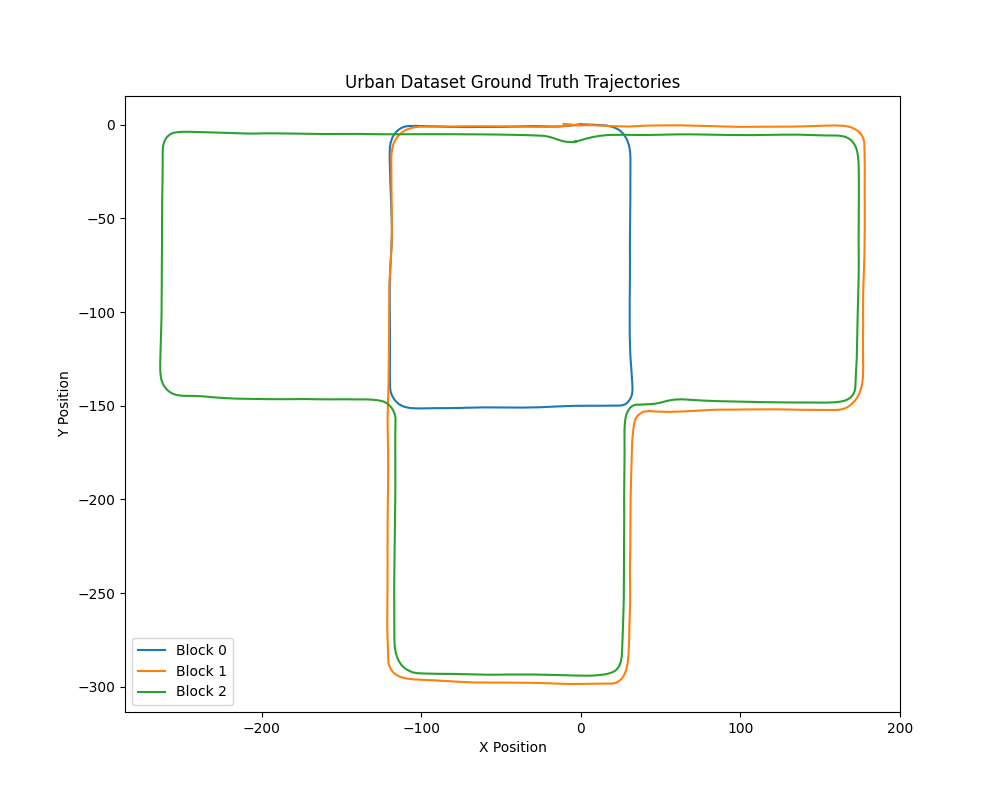

In [ ]:
# Visualize ground truth data for urban dataset
gt_dir = Path("/home/benb/data_byu/bags/urban/groundTruth")
gt1 = GroundTruthLoader(gt_dir / "block0_gt" / "optimized_poses.txt")
gt2 = GroundTruthLoader(gt_dir / "block1_gt" / "optimized_poses.txt")
gt3 = GroundTruthLoader(gt_dir / "block2_gt" / "optimized_poses.txt")

plt.figure(figsize=(10, 8))
plt.plot(gt1.gt_df["x"], gt1.gt_df["y"], label="Block 0", color="tab:blue")
plt.plot(gt2.gt_df["x"], gt2.gt_df["y"], label="Block 1", color="tab:orange")
plt.plot(gt3.gt_df["x"], gt3.gt_df["y"], label="Block 2", color="tab:green")
plt.title("Urban Dataset Ground Truth Trajectories")
plt.xlabel("X Position")
plt.ylabel("Y Position")
plt.legend()

🚀 Data stream detected. Initializing framework estimators
Reached 60 seconds in data stream loop.
Reached 120 seconds in data stream loop.
Reached 180 seconds in data stream loop.


Text(0.5, 1.0, 'Urban Block 0 Timestamps')

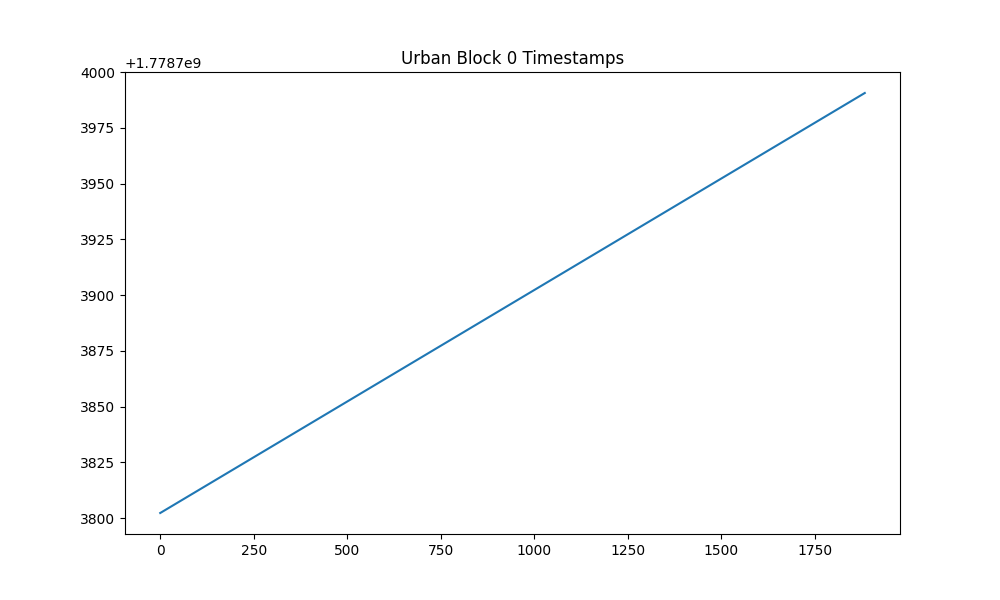

In [ ]:
bagReader = ReadTopicsFromRosbag(Path("/home/benb/data_byu/bags/urban/block0"))
timestamps = []

for topic, timestamp, xyz_points in bagReader.next_message():
    if timestamps:
        if timestamp <= timestamps[-1]:
            print(f"\033[93mWarning: Timestamp {timestamp} is not greater than the previous timestamp {timestamps[-1]}.\033[0m")
    timestamps.append(timestamp)
    # View with Open3D
    # pcd = o3d.geometry.PointCloud(o3d.utility.Vector3dVector(xyz_points))
    # break

# o3d.visualization.draw_geometries([pcd], window_name="Urban Block 0 Point Cloud", width=800, height=600)

plt.figure(figsize=(10, 6))
plt.plot(timestamps, label="Timestamps", color="tab:blue")
plt.title("Urban Block 0 Timestamps")